In [2]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 1.3 MB/s eta 0:00:38
    --------------------------------------- 1.0/48.9 MB 1.6 MB/s eta 0:00:31
   - -------------------------------------- 1.6/48.9 MB 1.6 MB/s eta 0:00:30
   - -------------------------------------- 2.1/48.9 MB 1.8 MB/s eta 0:00:27
   -- ------------------------------------- 2.6/48.9 MB 2.0 MB/s eta 0:00:24
   -- ------------------------------------- 3.7/48.9 MB 2.3 MB/s eta 0:00:20
   --- ------------------------------------ 4.2/48.9 MB 2.4 MB/s eta 0:00:19
   ---- ----------------------------------- 5.0/48.9 MB 2.5 MB/s eta 0:00:18
   ---- ----------------------------------- 5.8/48.9 MB 2.7 MB/s eta 0:00:17
   ----- ---------------------------------- 6.6/48.9 MB 2.7 MB/s eta 0:00:16
   ----- -----------

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

%matplotlib inline
sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("Wholesale-customers-data.csv")

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
X = df.drop('Channel', axis=1)
y = df['Channel'].map({1:1, 2:0})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [5]:
params = {
    'objective':'binary:logistic',
    'max_depth':4,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

model = XGBClassifier(**params)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9090909090909091

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.92      0.85        38
           1       0.97      0.90      0.93        94

    accuracy                           0.91       132
   macro avg       0.88      0.91      0.89       132
weighted avg       0.92      0.91      0.91       132



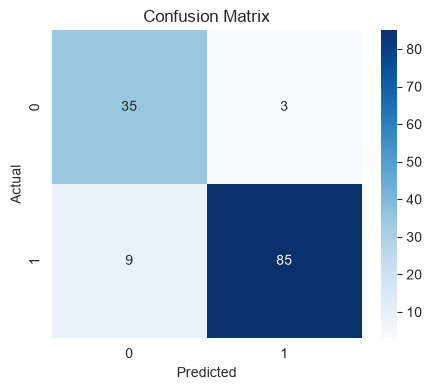

In [7]:
plt.figure(figsize=(5,4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<Figure size 800x600 with 0 Axes>

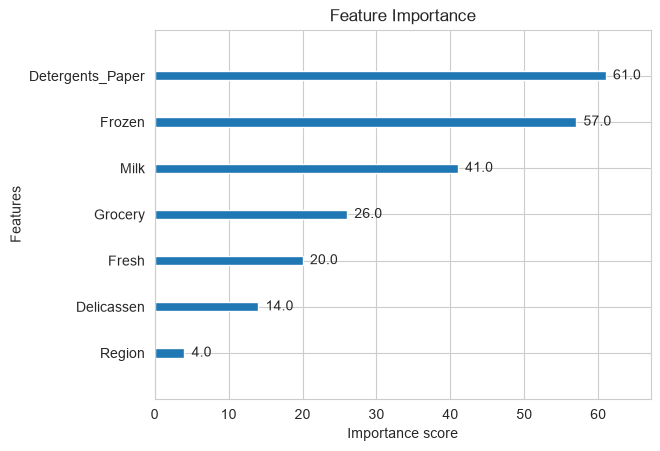

In [8]:
plt.figure(figsize=(8,6))
xgb.plot_importance(model)
plt.title("Feature Importance")
plt.show()

In [ ]:
plt.figure(figsize=(20,10))
xgb.plot_tree(model, num_trees=0)
plt.show()